*The code in this notebook was generated with the assistance of Claude.*

# Lab Activity 6 Solution: Missing Data, Regularization, Logistic Regression

## Part 1: Missing Data and Imputation

Question 1 in this section asks you to execute `in_class_notebooks/missing_data_and_imputation.ipynb` and answer some questions. The solutions given here assume you have done this and are working from that notebook. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression

framingham = pd.read_csv("../../data/framingham.csv")

**Q1a**: One of the cells in the notebook errors out. Why? 

**A1a:** The cell that fits `LinearRegression` before dropping any rows fails with `ValueError: Input X contains NaN`. sklearn's `LinearRegression` does not accept missing values, and the Framingham data has missing values in two of the predictors (`cigsPerDay` and `BMI`) and in the target (`totChol`). sklearn makes us decide what to do about missing values ourselves, either by dropping rows or by imputing.

**Q1b** What does the correlation plot tell us?

**A1b:** All of the correlations are weak to moderate. The target, `totChol`, is only weakly correlated with each predictor (largest: `age` then `sysBP`), so we should expect a low $R^2$. Among the predictors, `sysBP` has the strongest correlation with `age` (0.39) and `BMI`. No pair of predictors is correlated strongly enough to make multicollinearity a concern.

**Q1c** We delete 80% of the values of `sysBP`. Based on how we did the deletion, is the missing `sysBP` data MAR, MNAR, or MCAR?

**Q1c** The missing data is MCAR, missing completely at random, since we randomly deleted 80% of the data without regard to anything else. Whether a row loses its `sysBP` value doesn't depend on that patient's `sysBP` (which would be MNAR) or on any other variable in the data (which would be MAR). 

The code snippet below is a way to gut check this assessment. `.sample(frac=0.8, random_state=567)` picks 80% of the rows uniformly at random. The displayed table then shows the mean values of age, cigarettes per day, BMI, total Cholesterol, and sysBP. The patients whose `sysBP` was deleted have about the same average age, smoking, BMI, cholesterol, and even true `sysBP` as the patients whose `sysBP` was kept.

In [2]:
# Same deletion as in the notebook
missing_framingham = framingham.copy()
missing_framingham.loc[missing_framingham.sample(frac=0.8, random_state=567).index, "sysBP"] = np.nan

# Compare patients whose sysBP was deleted with those whose sysBP was kept
is_missing = missing_framingham["sysBP"].isna().rename("sysBP deleted")
framingham.groupby(is_missing)[["age", "cigsPerDay", "BMI", "totChol", "sysBP"]].mean().round(2)

,age,cigsPerDay,BMI,totChol,sysBP
sysBP deleted,,,,,
False,49.92,9.16,25.81,234.95,133.95
True,49.49,8.97,25.80,237.14,131.96


**Q1d** In Approach #2 we fit a second model with significantly fewer data points than our baseline and plot the coefficient values for each model. What does this plot tell you about the impact of removing `sysBP` on coefficient estimates?

**A1d:** Losing about 80% of the rows increases the confidence intervals around each of the coefficient estimates across all coefficients, not simply sysBP (the variable that is missing) but the other coefficients as well. Every model 1 estimate still falls within the model 2 error bars, even if the coefficients themselves change. 

**Q1e** In Approach #3, we used mean imputation for the missing `sysBP` values. Why might we have used the mean from the dataset with 80% of the values missing, rather than the mean from the entire dataset we started with?

**A1e:** We are simulating a real missing-data problem, and in a real problem we never see the values that are missing. The only mean we could actually compute is the mean of the observed values. Using the mean from the full original data would use information that we pretended to delete. That would make mean imputation look better than it would in practice. This is the same idea as fitting a scaler or imputer on the training data only, so no information leaks in from data the model shouldn't see. 

## Part 2: Regularization

## Setup (provided)
Note: I am excluding the numpy, pandas, and matplotlib imports here since I already did them above. 

In [3]:
from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

auto = pd.read_csv("../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]

# Same 5-fold CV object for all methods, so the results are comparable
SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Grid of penalty strengths (sklearn's alpha = glmnet's lambda) to search over
# Remember: We don't know what the right penalty is, we are trying to find it!
alphas = np.logspace(-3, 3, 100)
auto.shape

(392, 9)

### Q1: OLS baselines

Fit OLS on standardized features (1) with all five numeric features and (2) with `horsepower`, `weight`, and `year` only.

In [4]:
#Q1a - Output the coefficients for both models in a table. 

ols_all = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)

sel = ["horsepower", "weight", "year"]
ols_sel = make_pipeline(StandardScaler(), LinearRegression()).fit(X[sel], y)

# One table that we add a column to in each question. Features not in a model show NaN.
coef_table = pd.DataFrame({
    "OLS (all 5)": ols_all[-1].coef_,
    "OLS (hp, wt, yr)": pd.Series(ols_sel[-1].coef_, index=sel),
}, index=num)
coef_table.round(3)

,OLS (all 5),"OLS (hp, wt, yr)"
displacement,0.291,NaN
horsepower,0.039,-0.192
weight,-5.831,-5.470
acceleration,0.249,NaN
year,2.774,2.755


**Q1b** Why is standardization required for ridge and lasso regression, when for OLS it changed only how we interpret the coefficients, but not the fit of the model?

**A1b:** The ridge and lasso penalties are applied directly to the size of the coefficients, and larger coefficients are penalized more heavily. Standardizing puts all of the features on the same scale, so the penalty treats them equally. OLS has no penalty, so its fitted values don't change when you rescale a feature. Only the coefficients' units change.

### Q2: Ridge regression

**(a)** Use `RidgeCV(alphas=alphas, cv=cv)` in a pipeline with `StandardScaler()` to fit a ridge model.

**(b)** Report the penalty (`.alpha_`) and add the coefficients to the table.

In [5]:
# Q2 a+b
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=cv)).fit(X, y)
print("chosen alpha:", round(ridge[-1].alpha_, 3))

coef_table["Ridge"] = ridge[-1].coef_
coef_table.round(3)

chosen alpha: 1.233


,OLS (all 5),"OLS (hp, wt, yr)",Ridge
displacement,0.291,NaN,0.147
horsepower,0.039,-0.192,-0.044
weight,-5.831,-5.470,-5.634
acceleration,0.249,NaN,0.201
year,2.774,2.755,2.753


In [6]:
# (c) How much did each coefficient change from the full OLS model?
pd.DataFrame({
    "OLS (all 5)": coef_table["OLS (all 5)"],
    "Ridge": coef_table["Ridge"],
    "change": coef_table["Ridge"] - coef_table["OLS (all 5)"],
    "% change": 100 * (coef_table["Ridge"] - coef_table["OLS (all 5)"]) / coef_table["OLS (all 5)"].abs(),
}).round(3)

,OLS (all 5),Ridge,change,% change
displacement,0.291,0.147,-0.143,-49.345
horsepower,0.039,-0.044,-0.084,-213.094
weight,-5.831,-5.634,0.197,3.382
acceleration,0.249,0.201,-0.048,-19.182
year,2.774,2.753,-0.022,-0.782


**Q2c** Are any of the ridge coefficients exactly zero? Compare the ridge coefficients to the full OLS model. Which coefficients changed the most?

**Answer (c):** No. Ridge shrinks coefficients *toward* zero but never sets them exactly to zero, so all five features stay in the model. In absolute terms, `weight` moved the most (about 0.2 mpg per SD, from −5.83 to −5.63). In relative terms, the biggest changes are in the correlated group: `displacement` shrinks by more than half, and `horsepower` changes sign from slightly positive to slightly negative. 

### Q3: Lasso regression

**(a)** Use `LassoCV(alphas=alphas, cv=cv)` in a pipeline with `StandardScaler()` to fit a lasso model.

**(b)** Report the penalty (`.alpha_`) and add the coefficients to the table. Which features did the lasso model drop?

In [7]:
#Q3a+b
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv)).fit(X, y)
print("chosen alpha:", round(lasso[-1].alpha_, 3))

coef_table["Lasso"] = lasso[-1].coef_
print("dropped:", list(coef_table.index[coef_table["Lasso"] == 0]))
coef_table.round(3)

chosen alpha: 0.05
dropped: ['displacement', 'horsepower']


,OLS (all 5),"OLS (hp, wt, yr)",Ridge,Lasso
displacement,0.291,NaN,0.147,-0.000
horsepower,0.039,-0.192,-0.044,-0.000
weight,-5.831,-5.470,-5.634,-5.532
acceleration,0.249,NaN,0.201,0.154
year,2.774,2.755,2.753,2.721


**Answer (b):** The lasso chose alpha ≈ 0.05 and set `displacement` and `horsepower` exactly to zero. It kept `weight` (≈ −5.5), `year` (≈ +2.7), and `acceleration` (≈ +0.15). 

**Q2c** For a lasso model that chooses three coefficients, why might we trust this more than a forward/backward selection with k = 3? What limits might the lasso have?

**Answer (c):** Note: You do not need to list all of the answers below to get full credit. 

Reasons to prefer the Lasso:
- **It doesn't need us to choose k.** Forward/backward selection with k = 3 keeps three features because we told it to. The lasso keeps three because cross-validation chose the penalty that predicts best out of sample, and that penalty happened to zero out two features.
- **It considers all features at once.** Forward and backward selection are greedy: they add or remove one feature at a time and never revisit a decision, so they can miss a better subset. The lasso fits a single optimization over all of the coefficients together.
- **It shrinks as well as selects.** The kept coefficients are pulled toward zero, which lowers their variance, and creates more stable estimates. 

Limits of the lasso:
- **Correlated features.** From a group of highly correlated features, the lasso tends to keep one and drop the rest, and which one it keeps can change with a small change in the data or the CV seed. 
- **Biased coefficients.** Shrinkage biases the kept coefficients toward zero, so they can understate the effect sizes. A common fix is to refit OLS on the features the lasso kept. (Relaxed Lasso)
- **Depends on scaling and on the alpha grid.** The answer changes if the features aren't standardized, and the chosen alpha (and therefore which features survive) can vary with the CV split.


### Q4: Elastic Net

**(a)** Use `ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv)` in a pipeline with `StandardScaler()`.

**(b)** Report the chosen `alpha_`, the chosen `l1_ratio_`, and the coefficients, and add them to the table. What does the chosen `l1_ratio_` tell you?

In [8]:
enet = make_pipeline(StandardScaler(),
                     ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9, 1], cv=cv)).fit(X, y)
print("chosen alpha:   ", round(enet[-1].alpha_, 3))
print("chosen l1_ratio:", enet[-1].l1_ratio_)

coef_table["Elastic Net"] = enet[-1].coef_
coef_table.round(3)

chosen alpha:    0.05
chosen l1_ratio: 1.0


,OLS (all 5),"OLS (hp, wt, yr)",Ridge,Lasso,Elastic Net
displacement,0.291,NaN,0.147,-0.000,-0.000
horsepower,0.039,-0.192,-0.044,-0.000,-0.000
weight,-5.831,-5.470,-5.634,-5.532,-5.532
acceleration,0.249,NaN,0.201,0.154,0.154
year,2.774,2.755,2.753,2.721,2.721


**Answer (b):** Cross-validation chose `l1_ratio = 1` and the same alpha as the lasso (≈ 0.05). An `l1_ratio` of 1 is a pure lasso penalty with no ridge part, so the elastic net coefficients are identical to the lasso coefficients from Q3. CV is telling us that, for this data, mixing in a ridge penalty does not improve out-of-sample prediction. 

**(c)** Looking at all of the approaches in this part of the lab, which features do the different methods agree are important?

**Answer (c):** Every method agrees that **`weight`** and **`year`** are the important features, with similar coefficients: about −5.5 to −5.8 mpg per SD of weight (heavier cars get worse mileage) and about +2.7 to +2.8 mpg per SD of year (newer cars get better mileage). Every method also gives the other three features small coefficients:
- `displacement` is dropped by the lasso and elastic net and close to zero in ridge and full OLS. (For the OLS with a subset of variables, we chose to exclude it.)
- `horsepower` and `acceleration` each have a coefficient of about 0.2 or less wherever they appear. Which of the two gets included as a "third feature" depends on the method (and in Lab 5, on the seed).

## Part 3: Logistic Regression 

## Setup (provided)

The provided setup uses `[numeric]` as a placeholder for the numeric column (`age` for Model A, `cigsPerDay` for Model B). 

I am adding a small function in addition to the Setup code I provided in class. To build both models from the same code, we put the provided `preprocess` step inside a small function, `make_model`, that takes the numeric column as an argument. Note that this setup overwrites `X`, `y`, and `cv` from Part 2.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline


# Same data preparation as in class: drop rows with any missing values
fram = pd.read_csv("../../data/framingham.csv").dropna()
y = fram["TenYearCHD"]

# Same CV object as in class. Stratified folds keep the ~15% CHD rate in every fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def make_model(numeric):
    # Preprocess by scaling numeric variables using Standard Scaler
    # You don't need to scale or one hot encode the binary male categorical variable
    preprocess = ColumnTransformer(transformers=[
        ("binary", "passthrough", ["male"]),
        ("numeric", StandardScaler(), [numeric]),
    ])
    return Pipeline(steps=[("preprocess", preprocess), ("model", LogisticRegression())])

### Q1: Baselines

**(a)** What fraction of the patients developed CHD within 10 years?

**(b)** Suppose a "model" predicts no CHD for every patient. What is its accuracy?

**(c)** Suppose a "model" predicts the same probability for every patient, equal to the fraction in (a). What is its log loss?

In [10]:
base_rate = y.mean()
print(f"(a) CHD rate: {base_rate:.4f}")

print(f"(b) Accuracy of predicting 'no CHD' for everyone: {accuracy_score(y, np.zeros(len(y))):.4f}")

ll_base = log_loss(y, np.full(len(y), base_rate))
print(f"(c) Log loss, base rate for everyone: {ll_base:.4f}")

(a) CHD rate: 0.1523
(b) Accuracy of predicting 'no CHD' for everyone: 0.8477
(c) Log loss, base rate for everyone: 0.4266


**Answer (a):** About 15.2% of patients developed CHD. The classes are imbalanced.

**Answer (b):** About 84.8%. A "model" that never predicts CHD looks very accurate, but it identifies zero CHD cases. A real model has to beat 84.8% before its accuracy means anything.

**Answer (c):** About 0.427. This is the bar to beat. A model that uses `male` and a numeric variable should have a log loss below 0.427. If it doesn't, it has learned nothing beyond the overall CHD rate. (For comparison, a coin flip, $\hat p = 0.5$ for everyone, has a log loss of $\ln 2 \approx 0.693$.)

### Q2: Fit both models and compute log loss

**(a)** Fit Model A (`male` + `age`) and Model B (`male` + `cigsPerDay`).

**(b)** For each model, get the predicted probabilities of CHD with `predict_proba` and compute the log loss with sklearn's `log_loss`.

**(c)** For Model A, compute the log loss by hand with NumPy. It should match the value from sklearn.

In [11]:
X_A = fram[["male", "age"]]
X_B = fram[["male", "cigsPerDay"]]

model_A = make_model("age").fit(X_A, y)
model_B = make_model("cigsPerDay").fit(X_B, y)

# Column 1 of predict_proba is P(TenYearCHD = 1)
p_A = model_A.predict_proba(X_A)[:, 1]
p_B = model_B.predict_proba(X_B)[:, 1]

print(f"(b) Model A log loss (sklearn): {log_loss(y, p_A):.4f}")
print(f"    Model B log loss (sklearn): {log_loss(y, p_B):.4f}")

# (c) By hand: -(1/n) * sum[ y log(p) + (1 - y) log(1 - p) ]
ll_by_hand = -np.mean(y * np.log(p_A) + (1 - y) * np.log(1 - p_A))
print(f"(c) Model A log loss (by hand): {ll_by_hand:.4f}")

(b) Model A log loss (sklearn): 0.3942
    Model B log loss (sklearn): 0.4222
(c) Model A log loss (by hand): 0.3942


**Notes on Part (b):** In sample, Model A has a log loss of about 0.394 and Model B about 0.422. Model A's is lower (better). Only Model A is well below the base-rate log loss of 0.427 from Q1. Model B barely beats it.

**Notes on Part (c):** The NumPy calculation gives exactly the same number as `log_loss`. `np.mean` does the $\frac{1}{n}\sum$, matching sklearn, which reports the **average** log loss per patient, not the sum.

### Q3: Which model is better?

The numbers in Q2 are in sample (each model was scored on the same data it was fit on), so we use cross-validation to compare them.

**(a)** Use `cross_validate` with the `cv` object from the setup and `scoring=["accuracy", "neg_log_loss", "roc_auc"]` to evaluate both models. Report the mean and standard deviation across the 5 folds for each metric.

In [12]:
#Q3a
models = {"A: male + age": "age", "B: male + cigsPerDay": "cigsPerDay"}

rows = {}
for name, numeric in models.items():
    res = cross_validate(make_model(numeric), fram[["male", numeric]], y, cv=cv,
                         scoring=["accuracy", "neg_log_loss", "roc_auc"])
    rows[name] = {
        "accuracy (mean)": res["test_accuracy"].mean(),
        "accuracy (sd)": res["test_accuracy"].std(ddof=1),
        "log loss (mean)": -res["test_neg_log_loss"].mean(),   # flip sklearn's sign back
        "log loss (sd)": res["test_neg_log_loss"].std(ddof=1),
        "AUC (mean)": res["test_roc_auc"].mean(),
        "AUC (sd)": res["test_roc_auc"].std(ddof=1),
    }

pd.DataFrame(rows).T.round(4)

,accuracy (mean),accuracy (sd),log loss (mean),log loss (sd),AUC (mean),AUC (sd)
A: male + age,0.8480,0.0011,0.3953,0.0149,0.7013,0.0443
B: male + cigsPerDay,0.8477,0.0007,0.4233,0.0025,0.5645,0.0356


**Answer (a):** See the table. We report the mean and standard deviation of the 5 per-fold scores, not one score computed from all of the predictions pooled together. (Note: We are cross-validating on all of the data rather than also holding out a final test set for evaluation at the end, since we are only comparing two fixed models, not tuning anything.

**(b)** Compare the CV accuracy of the two models with the baseline accuracy from Q1(b). Is accuracy a useful metric for choosing between these models?

**Answer (b):** No. Both models have CV accuracy of about 0.848, the same as predicting "no CHD" for everyone (Q1b). Accuracy can't tell the two models apart because it only looks at the predicted *class* at a threshold of 0.5 and ignores how good the predicted *probabilities* are. 

**Q3c** Use `cross_val_predict` with `method="predict_proba"` to get out-of-fold predicted probabilities for each model. Plot the confusion matrices for both models at thresholds of 0.5 and 0.2. What do you observe?

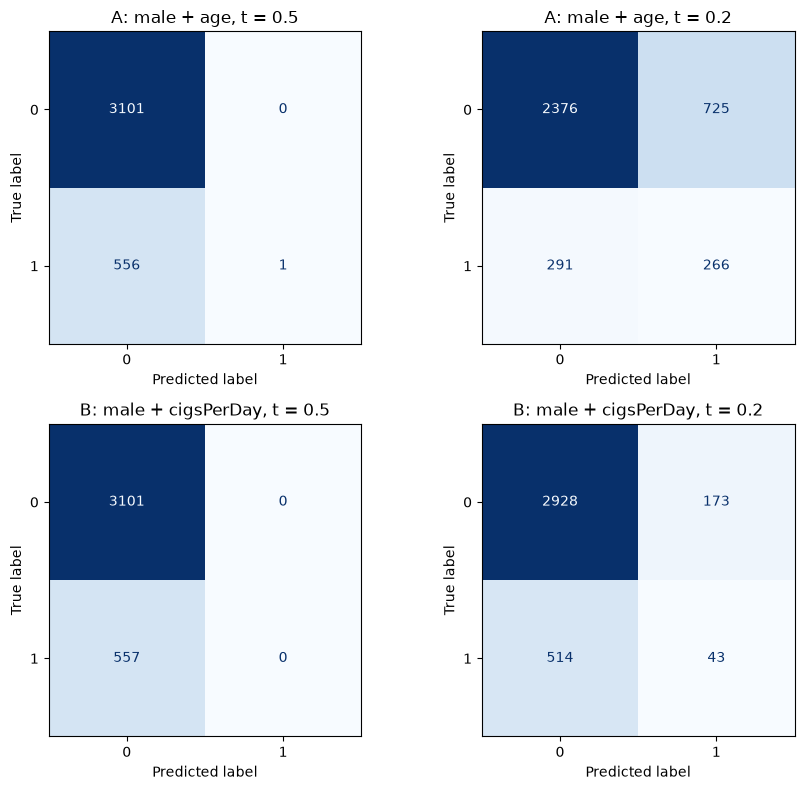

In [13]:
# Q3c
# Out-of-fold probabilities. Pooling them is fine for a confusion matrix;
# the summary metrics in the table above use per-fold scores.
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for row, (name, numeric) in enumerate(models.items()):
    p_cv = cross_val_predict(make_model(numeric), fram[["male", numeric]], y, cv=cv,
                             method="predict_proba")[:, 1]
    for col, t in enumerate([0.5, 0.2]):
        ConfusionMatrixDisplay.from_predictions(y, (p_cv >= t).astype(int), ax=axes[row, col],
                                                cmap="Blues", colorbar=False)
        axes[row, col].set_title(f"{name}, t = {t}")
plt.tight_layout()
plt.show()

**Answer (c):** At t = 0.5, both confusion matrices are almost identical to the "predict no CHD for everyone" baseline: Model A flags one patient as positive and Model B flags none. With only 15% positives and only two predictors, the models almost never predict a probability of 0.5 or higher. Their accuracy matches the baseline because they are doing the same thing as the baseline.

At t = 0.2 (the threshold we tried in class), the models finally separate. Model A correctly identifies about 266 of the 557 CHD cases, at the cost of about 725 false positives. Model B identifies only about 43 (with about 173 false positives).

**Q3d** Based on the log loss, ROC AUC, and confusion matrices, which model would you choose and why? Relate your answer to the log loss of the "model" in Q1.

**Answer (d):** **Model A** (`male` + `age`). Every threshold-free metric favors it:
- **Log loss:** Model A's CV log loss (≈ 0.395) is clearly lower than Model B's (≈ 0.423). The gap (≈ 0.028) is about twice the larger of the two fold-to-fold standard deviations, so it isn't just noise.
- **Comparison with the Q1 baseline:** predicting the base rate of 15.2% for everyone gives a log loss of 0.427. Model A improves on that by about 0.03. Model B improves on it by only about 0.003, so knowing a patient's sex and how much they smoke adds very little beyond the overall CHD rate. Model B is barely better than the constant-probability "model".
- **ROC AUC:** ≈ 0.70 for Model A vs ≈ 0.56 for Model B, where 0.5 is random guessing. Model A ranks patients by risk much better.
- **Confusion matrices:** at t = 0.2, Model A catches about six times as many CHD cases as Model B.

